# DP2 Optical Photometry Diagnostics

## Rubin DP2 vs LSST–VISTA Fusion

**Field:** ELAIS-S1  
**Skymap:** `lsst_cells_v2_dp2`  
**Tract:** 2877  
**Patch:** 77  
**Optical bands:** u, g, r, i, z, y  

### Objective

Validate the reconstructed Rubin DP2 optical photometry from
the LSST–VISTA Fusion pipeline against the official Rubin DP2
Object catalogues.

### Input data

- Rubin DP2 Object catalogues downloaded from the Rubin Science Platform
- Fusion Step3c unforced and forced measurement catalogues
- Fusion collection: `fusionStep3cDP2Full`

### Validation

- Astrometric agreement
- PSF photometric agreement
- Flux and magnitude residuals
- Dependence on magnitude, S/N, and sky position
- Source matching and catalogue completeness

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

from lsst.daf.butler import Butler
import lsst.afw.table as afwTable

# --------------------------------------------------
# Directories
# --------------------------------------------------

BASE_DIR = Path(
    "/local/scratch/es3e23/projects/lsst-ir-fusion"
)

DIAG_DIR = BASE_DIR / "dmu5/dmu5_DP2/diagnostics"

RSP_DIR = DIAG_DIR / "data/optical-RSP-object-catalog"

REPO = BASE_DIR / "dmu4/dmu4_DP2/dmu4_DP2_Example/data"

# --------------------------------------------------
# Butler configuration
# --------------------------------------------------

FUSION_COLLECTION = "fusionStep3cDP2Full"

SKYMAP = "lsst_cells_v2_dp2"
TRACT = 2877
PATCH = 77

OPTICAL_BANDS = ["u", "g", "r", "i", "z", "y"]

# --------------------------------------------------
# Output directories
# --------------------------------------------------

FIG_DIR = DIAG_DIR / "data/figures"
RESULT_DIR = DIAG_DIR / "data/results"

FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Connect to Butler
# --------------------------------------------------

butler = Butler.from_config(
    str(REPO),
    collections=[FUSION_COLLECTION],
)

# --------------------------------------------------
# Check RSP catalogue files
# --------------------------------------------------

print("Diagnostics directory:", DIAG_DIR)
print("Butler repository:", REPO)
print("Fusion collection:", FUSION_COLLECTION)
print("Tract / patch:", TRACT, PATCH)
print("Optical bands:", OPTICAL_BANDS)

print("\nRSP catalogue directory:", RSP_DIR)

if RSP_DIR.exists():
    files = sorted(RSP_DIR.glob("*"))

    print(f"Found {len(files)} files:\n")

    for file in files:
        if file.is_file():
            print(f"  {file.name}")
else:
    print("RSP catalogue directory not found yet.")

Diagnostics directory: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics
Butler repository: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu4/dmu4_DP2/dmu4_DP2_Example/data
Fusion collection: fusionStep3cDP2Full
Tract / patch: 2877 77
Optical bands: ['u', 'g', 'r', 'i', 'z', 'y']

RSP catalogue directory: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/optical-RSP-object-catalog
Found 1 files:

  DP2_object_tract2877_patch77_optical.fits


In [2]:
rsp_file = RSP_DIR / f"DP2_object_tract{TRACT}_patch{PATCH}_optical.fits"

rubin = Table.read(rsp_file, hdu=1)

print("Rubin DP2 Object catalogue")
print("--------------------------")
print("Number of objects:", len(rubin))
print("Number of columns:", len(rubin.colnames))

print("\nAvailable PSF photometry:")
for band in OPTICAL_BANDS:
    cols = [
        f"{band}_psfFlux",
        f"{band}_psfFluxErr",
        f"{band}_psfFlux_flag",
    ]
    missing = [c for c in cols if c not in rubin.colnames]
    print(f"{band}: {'OK' if not missing else 'Missing: ' + ', '.join(missing)}")

print("\nCoordinate columns:")
print(rubin["coord_ra"][:3])
print(rubin["coord_dec"][:3])

Rubin DP2 Object catalogue
--------------------------
Number of objects: 10005
Number of columns: 22

Available PSF photometry:
u: OK
g: OK
r: OK
i: OK
z: OK
y: OK

Coordinate columns:
     coord_ra    
-----------------
9.665517584734042
9.612505263079877
  9.5760315475721
     coord_dec     
-------------------
 -43.54936531853445
 -43.54914376213881
-43.548878461211324


## 2. Fusion optical catalogues

Load the unforced PSF measurement catalogues from the completed
LSST–VISTA Fusion Step3c run for all six optical bands.

Check the number of detected sources and the availability of
PSF fluxes, uncertainties, and measurement flags.

In [4]:
# Load optical unforced measurement catalogues from Butler

fusion_cats = {}

for band in OPTICAL_BANDS:

    data_id = {
        "skymap": SKYMAP,
        "tract": TRACT,
        "patch": PATCH,
        "band": band,
    }

    cat = butler.get(
        "object_unforced_measurement",
        dataId=data_id,
    )

    fusion_cats[band] = cat

    print(f"\nBand: {band}")
    print(f"  Sources: {len(cat):,}")

    for col in [
        "coord_ra",
        "coord_dec",
        "base_PsfFlux_instFlux",
        "base_PsfFlux_instFluxErr",
        "base_PsfFlux_flag",
    ]:
        print(f"  {col}: {'OK' if col in cat.schema.getNames() else 'MISSING'}")


Band: u
  Sources: 13,266
  coord_ra: OK
  coord_dec: OK
  base_PsfFlux_instFlux: OK
  base_PsfFlux_instFluxErr: OK
  base_PsfFlux_flag: OK

Band: g
  Sources: 13,266
  coord_ra: OK
  coord_dec: OK
  base_PsfFlux_instFlux: OK
  base_PsfFlux_instFluxErr: OK
  base_PsfFlux_flag: OK

Band: r
  Sources: 13,266
  coord_ra: OK
  coord_dec: OK
  base_PsfFlux_instFlux: OK
  base_PsfFlux_instFluxErr: OK
  base_PsfFlux_flag: OK

Band: i
  Sources: 13,266
  coord_ra: OK
  coord_dec: OK
  base_PsfFlux_instFlux: OK
  base_PsfFlux_instFluxErr: OK
  base_PsfFlux_flag: OK

Band: z
  Sources: 13,266
  coord_ra: OK
  coord_dec: OK
  base_PsfFlux_instFlux: OK
  base_PsfFlux_instFluxErr: OK
  base_PsfFlux_flag: OK

Band: y
  Sources: 13,266
  coord_ra: OK
  coord_dec: OK
  base_PsfFlux_instFlux: OK
  base_PsfFlux_instFluxErr: OK
  base_PsfFlux_flag: OK


### 3. Astrometric matching

Cross-match the Fusion optical measurement catalogue with the official
Rubin DP2 Object catalogue using sky coordinates.

Use a matching radius of 0.5 arcsec and calculate the number of
matched sources, matching fractions, and positional residuals.

The match is initially based on nearest-neighbour positions; we will
check for duplicate associations before using matched objects for
photometric comparisons.

In [5]:
# Use i band as the reference for positional matching
# All six Fusion optical catalogues share a common source list.

fusion_ref = fusion_cats["i"]

rubin_coords = SkyCoord(
    ra=np.asarray(rubin["coord_ra"]) * u.deg,
    dec=np.asarray(rubin["coord_dec"]) * u.deg,
)

fusion_coords = SkyCoord(
    ra=np.asarray(fusion_ref["coord_ra"]) * u.rad,
    dec=np.asarray(fusion_ref["coord_dec"]) * u.rad,
)

# Nearest Rubin object for each Fusion source
match_idx, separation, _ = fusion_coords.match_to_catalog_sky(
    rubin_coords
)

MATCH_RADIUS = 0.5  # arcsec

matched = separation.arcsec < MATCH_RADIUS

n_fusion = len(fusion_ref)
n_rubin = len(rubin)
n_matched = np.count_nonzero(matched)
n_unique_rubin = len(np.unique(match_idx[matched]))

print("Astrometric matching results")
print("-----------------------------")
print(f"Fusion sources:               {n_fusion:,}")
print(f"Rubin DP2 objects:            {n_rubin:,}")
print(f"Matches (< {MATCH_RADIUS}\"):           {n_matched:,}")
print(f"Unique Rubin objects matched: {n_unique_rubin:,}")

print(f"\nFusion matching fraction:     {100*n_matched/n_fusion:.2f}%")
print(f"Rubin matching fraction:      {100*n_unique_rubin/n_rubin:.2f}%")

print("\nPositional separation:")
print(f"Median: {np.median(separation.arcsec[matched]):.5f} arcsec")
print(f"90th percentile: {np.percentile(separation.arcsec[matched], 90):.5f} arcsec")
print(f"95th percentile: {np.percentile(separation.arcsec[matched], 95):.5f} arcsec")

print("\nDuplicate nearest-neighbour associations:",
      n_matched - n_unique_rubin)

Astrometric matching results
-----------------------------
Fusion sources:               13,266
Rubin DP2 objects:            10,005
Matches (< 0.5"):           9,818
Unique Rubin objects matched: 9,818

Fusion matching fraction:     74.01%
Rubin matching fraction:      98.13%

Positional separation:
Median: 0.00539 arcsec
90th percentile: 0.13413 arcsec
95th percentile: 0.17459 arcsec

Duplicate nearest-neighbour associations: 0


### 3.1. Astrometric separation distribution

Visualise the angular separation between matched Fusion sources and
official Rubin DP2 objects.

Report the median and 95th-percentile separations to assess the
astrometric consistency of the reconstructed optical processing.

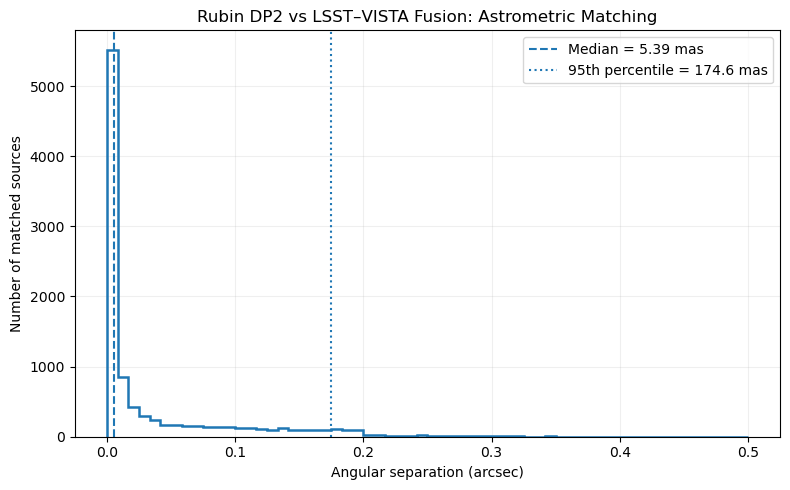

Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/figures/DP2_astrometry_tract2877_patch77.png


In [6]:
# Astrometric separation distribution

sep_matched = separation.arcsec[matched]

median_sep = np.median(sep_matched)
p95_sep = np.percentile(sep_matched, 95)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    sep_matched,
    bins=60,
    range=(0, MATCH_RADIUS),
    histtype="step",
    linewidth=1.8,
)

ax.axvline(
    median_sep,
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {median_sep*1000:.2f} mas",
)

ax.axvline(
    p95_sep,
    linestyle=":",
    linewidth=1.5,
    label=f"95th percentile = {p95_sep*1000:.1f} mas",
)

ax.set_xlabel("Angular separation (arcsec)")
ax.set_ylabel("Number of matched sources")
ax.set_title("Rubin DP2 vs LSST–VISTA Fusion: Astrometric Matching")

ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()

output = FIG_DIR / f"DP2_astrometry_tract{TRACT}_patch{PATCH}.png"
fig.savefig(output, dpi=200, bbox_inches="tight")

plt.show()

print("Saved:", output)

### Astrometric matching results

The LSST–VISTA Fusion catalogue contains 13,266 sources, compared
with 10,005 objects in the official Rubin DP2 Object catalogue.

Using a positional matching radius of 0.5 arcsec:

- **9,818 objects** have unique positional matches.
- **98.13%** of Rubin DP2 objects have Fusion counterparts.
- **74.01%** of Fusion sources have Rubin DP2 counterparts.
- The median positional separation is **5.39 mas**.
- The 95th-percentile separation is **174.6 mas**.
- No duplicate nearest-neighbour associations were found.

The separation distribution has a strong peak near zero,
indicating excellent positional agreement for most matched sources.

These results describe the agreement between the two multiband
catalogues, rather than individual-band detection completeness.

The additional Fusion sources and unmatched Rubin objects require
further investigation because the two catalogues represent different
processing and selection stages.

### 4. Multiband source consistency

Verify that all six Fusion optical catalogues contain the same
source IDs in the same order.

This check ensures that the astrometric matches derived from the
i-band catalogue can be reused safely for photometric comparisons
in all optical bands.

In [7]:
# Compare source IDs across all optical bands

reference_ids = np.asarray(fusion_cats["i"]["id"])

all_consistent = True

print("Multiband source consistency")
print("----------------------------")

for band in OPTICAL_BANDS:

    cat = fusion_cats[band]
    ids = np.asarray(cat["id"])

    same_length = len(ids) == len(reference_ids)

    same_order = (
        same_length
        and np.array_equal(ids, reference_ids)
    )

    print(
        f"{band}: N={len(ids):,} | "
        f"Same IDs and order: {same_order}"
    )

    if not same_order:
        all_consistent = False

print("\nAll bands consistent:", all_consistent)

Multiband source consistency
----------------------------
u: N=13,266 | Same IDs and order: True
g: N=13,266 | Same IDs and order: True
r: N=13,266 | Same IDs and order: True
i: N=13,266 | Same IDs and order: True
z: N=13,266 | Same IDs and order: True
y: N=13,266 | Same IDs and order: True

All bands consistent: True


### Multiband source consistency — Results

All six optical `object_unforced_measurement` catalogues contain
**13,266 sources**, with identical source IDs and ordering.

This confirms that the Fusion optical measurements share a common
multiband source catalogue.

The previously established 9,818 positional matches with the public
Rubin DP2 Object catalogue can therefore be used consistently across
all six bands.

Photometric quality and measurement validity will be evaluated
independently for each band.

### 5. PSF photometric comparison

Compare PSF photometry from the Fusion `object_unforced_measurement`
catalogues against the official Rubin DP2 Object catalogue.

Use positional matches within 0.5 arcsec and require:

- Finite, positive PSF fluxes and uncertainties in both catalogues.
- Unflagged PSF measurements in both catalogues.

Define the magnitude residual as:

$$
\Delta m = -2.5 \log_{10}\left(\frac{f_{\mathrm{Fusion}}}{f_{\mathrm{Rubin}}}\right)
$$

A negative residual means Fusion measures a brighter source.

Report the median residual, robust scatter (1.4826 × MAD),
and median flux ratio for each optical band.

In [8]:
# Six-band PSF photometry comparison

photometry_data = {}
summary_rows = []

for band in OPTICAL_BANDS:

    cat = fusion_cats[band]

    # Fusion measurements
    ff = np.asarray(cat["base_PsfFlux_instFlux"], dtype=float)
    ef = np.asarray(cat["base_PsfFlux_instFluxErr"], dtype=float)
    fusion_flag = np.asarray(cat["base_PsfFlux_flag"], dtype=bool)

    # Official Rubin DP2 measurements
    fr = np.asarray(rubin[f"{band}_psfFlux"], dtype=float)[match_idx]
    er = np.asarray(rubin[f"{band}_psfFluxErr"], dtype=float)[match_idx]
    rubin_flag = np.asarray(
        rubin[f"{band}_psfFlux_flag"], dtype=bool
    )[match_idx]

    # Quality selection
    good = (
        matched
        & np.isfinite(ff) & np.isfinite(fr)
        & np.isfinite(ef) & np.isfinite(er)
        & (ff > 0) & (fr > 0)
        & (ef > 0) & (er > 0)
        & ~fusion_flag
        & ~rubin_flag
    )

    flux_ratio = ff[good] / fr[good]
    delta_mag = -2.5 * np.log10(flux_ratio)
    delta_flux = ff[good] - fr[good]

    median_mag = np.median(delta_mag) if good.any() else np.nan

    scatter_mag = (
        1.4826 * np.median(np.abs(delta_mag - median_mag))
        if good.any() else np.nan
    )

    photometry_data[band] = {
        "good": good,
        "fusion_flux": ff[good],
        "rubin_flux": fr[good],
        "rubin_flux_err": er[good],
        "delta_mag": delta_mag,
        "delta_flux": delta_flux,
    }

    summary_rows.append({
        "Band": band,
        "N valid": int(good.sum()),
        "Median Δmag": median_mag,
        "Robust scatter": scatter_mag,
        "Median flux ratio": (
            np.median(flux_ratio) if good.any() else np.nan
        ),
        "Median Δflux (nJy)": (
            np.median(delta_flux) if good.any() else np.nan
        ),
    })

photometry_summary = pd.DataFrame(summary_rows)

display(
    photometry_summary.style.format({
        "Median Δmag": "{:+.5f}",
        "Robust scatter": "{:.5f}",
        "Median flux ratio": "{:.5f}",
        "Median Δflux (nJy)": "{:+.4f}",
    })
)

# Save summary
output = RESULT_DIR / (
    f"DP2_optical_photometry_summary_tract{TRACT}_patch{PATCH}.csv"
)

photometry_summary.to_csv(output, index=False)

print("\nSaved:", output)

,Band,N valid,Median Δmag,Robust scatter,Median flux ratio,Median Δflux (nJy)
0,u,2320,-0.01359,0.02214,1.01259,+4.2486
1,g,5809,-0.00331,0.00909,1.00305,+0.9529
2,r,5571,-0.00137,0.00938,1.00126,+0.7604
3,i,7631,-0.00291,0.00532,1.00269,+1.3421
4,z,5049,-0.00358,0.01096,1.00330,+3.3896
5,y,2944,-0.00241,0.01652,1.00222,+5.5920



Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/results/DP2_optical_photometry_summary_tract2877_patch77.csv


### PSF photometry — Results

The comparison includes 9,818 positionally matched sources, with
band-dependent quality selections applied to PSF measurements.

- **g, r, i, z, y:** Median magnitude differences range from
  approximately −0.0014 to −0.0036 mag.
- **u:** The largest median offset (−0.0136 mag) and robust
  scatter (0.0221 mag).
- **i:** The smallest robust scatter (0.0053 mag).
- **All bands:** The median residuals are negative, indicating
  slightly higher PSF fluxes in the Fusion measurements.

The median flux differences range from approximately +0.76 nJy
in r to +5.59 nJy in y.

Overall, the results demonstrate close photometric agreement
for matched, valid sources. Further diagnostics are needed to
understand the magnitude dependence, band-dependent residuals,
and differences in source selection.

### 5.2. PSF magnitude residuals versus magnitude

Examine the dependence of PSF photometric residuals on source brightness for all six optical bands.

For each band, plot the magnitude difference (Fusion − Rubin) against the official Rubin PSF magnitude.

The analysis includes:
- Individual matched sources with valid PSF photometry.
- Median magnitude residuals in magnitude bins.
- Robust scatter calculated using 1.4826 × MAD.

Negative residuals indicate brighter Fusion measurements. A systematic trend toward faint magnitudes may indicate additive flux differences, background effects, or measurement-selection differences.

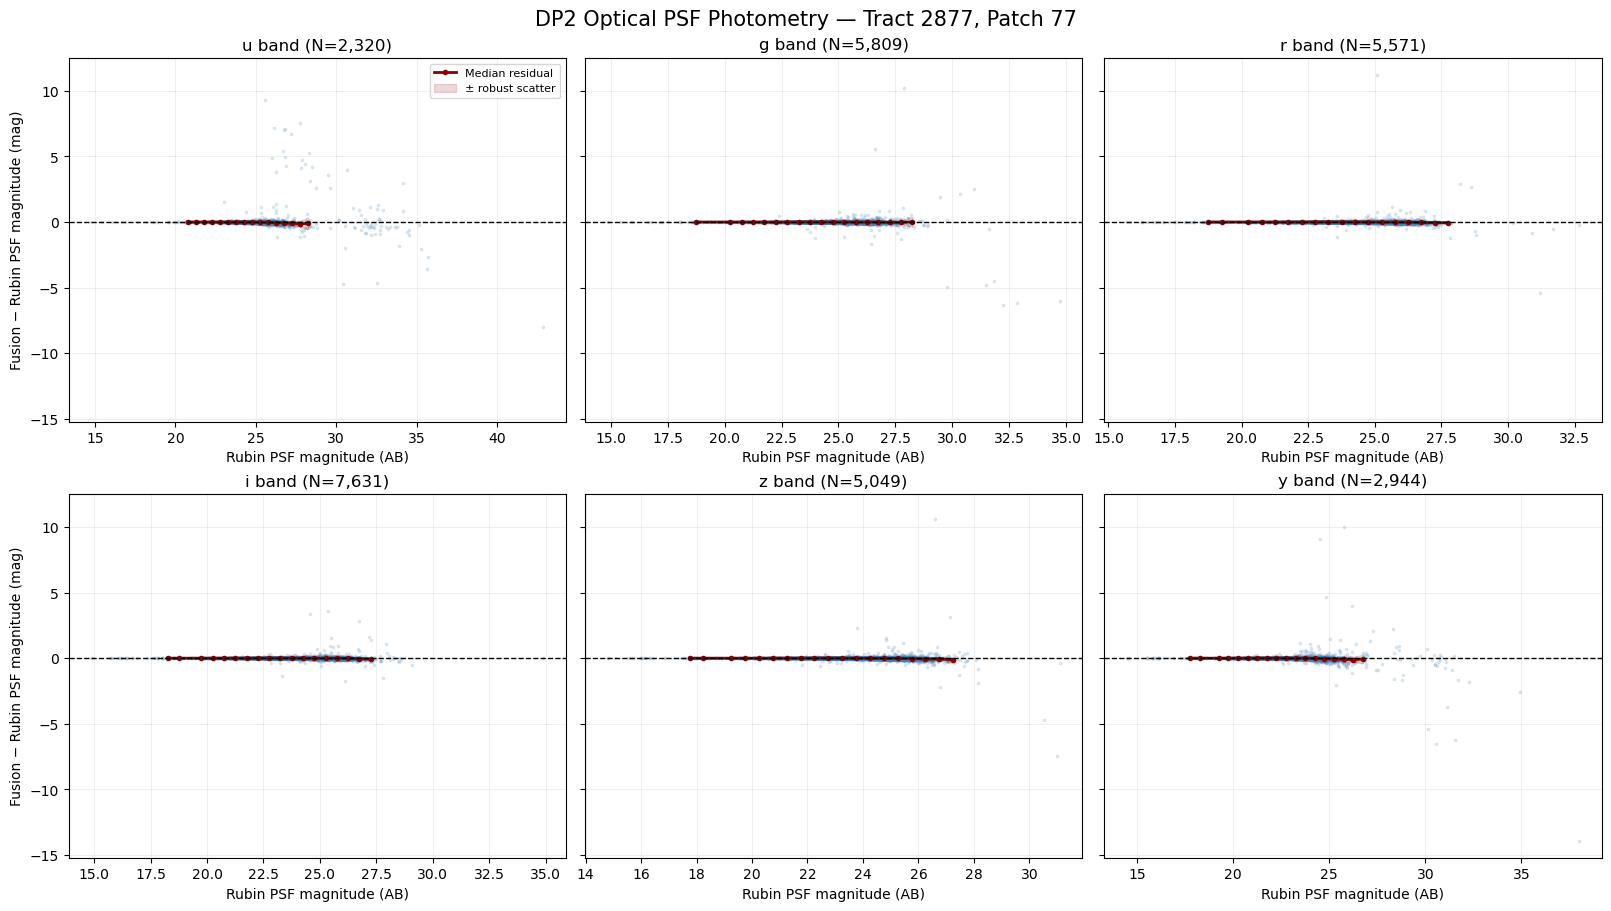

Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/figures/DP2_psf_magnitude_residuals_2877_77.png


In [9]:
# PSF magnitude residuals versus Rubin magnitude

fig, axes = plt.subplots(
    2, 3, figsize=(16, 9), sharey=True, constrained_layout=True
)

mag_bins = np.arange(17, 29, 0.5)
mag_centers = 0.5 * (mag_bins[:-1] + mag_bins[1:])

magnitude_results = {}

for ax, band in zip(axes.flat, OPTICAL_BANDS):

    data = photometry_data[band]

    # Rubin PSF flux in nJy
    rubin_flux = data["rubin_flux"]
    delta_mag = data["delta_mag"]

    # AB magnitude for flux in nJy
    rubin_mag = 31.4 - 2.5 * np.log10(rubin_flux)

    # Individual sources
    ax.scatter(
        rubin_mag,
        delta_mag,
        s=3,
        alpha=0.15,
        rasterized=True,
        color="steelblue"
    )

    medians = []
    scatters = []
    counts = []

    for lo, hi in zip(mag_bins[:-1], mag_bins[1:]):

        sel = (rubin_mag >= lo) & (rubin_mag < hi)
        d = delta_mag[sel]

        counts.append(len(d))

        if len(d) < 10:
            medians.append(np.nan)
            scatters.append(np.nan)
            continue

        med = np.median(d)
        scatter = 1.4826 * np.median(np.abs(d - med))

        medians.append(med)
        scatters.append(scatter)

    medians = np.asarray(medians)
    scatters = np.asarray(scatters)
    counts = np.asarray(counts)

    valid = np.isfinite(medians)

    # Median trend
    ax.plot(
        mag_centers[valid],
        medians[valid],
        color="darkred",
        linewidth=2,
        marker="o",
        markersize=3,
        label="Median residual"
    )

    # Robust scatter around median
    ax.fill_between(
        mag_centers[valid],
        medians[valid] - scatters[valid],
        medians[valid] + scatters[valid],
        color="darkred",
        alpha=0.15,
        label="± robust scatter"
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_title(f"{band} band (N={len(rubin_mag):,})")
    ax.set_xlabel("Rubin PSF magnitude (AB)")
    ax.grid(alpha=0.2)

    magnitude_results[band] = {
        "bin_centers": mag_centers,
        "median": medians,
        "scatter": scatters,
        "counts": counts
    }

for ax in axes[:, 0]:
    ax.set_ylabel("Fusion − Rubin PSF magnitude (mag)")

axes[0, 0].legend(fontsize=8)

fig.suptitle(
    f"DP2 Optical PSF Photometry — Tract {TRACT}, Patch {PATCH}",
    fontsize=15
)

output = FIG_DIR / f"DP2_psf_magnitude_residuals_{TRACT}_{PATCH}.png"
fig.savefig(output, dpi=200, bbox_inches="tight")

plt.show()

print("Saved:", output)

### 5.3. Magnitude residuals — Detailed view

Repeat the six-band PSF photometric comparison with a restricted
vertical axis to reveal small systematic offsets.

Display median magnitude residuals and robust scatter as functions
of Rubin PSF magnitude.

Only the plotting range is restricted; the photometric selection
and calculated statistics remain unchanged.

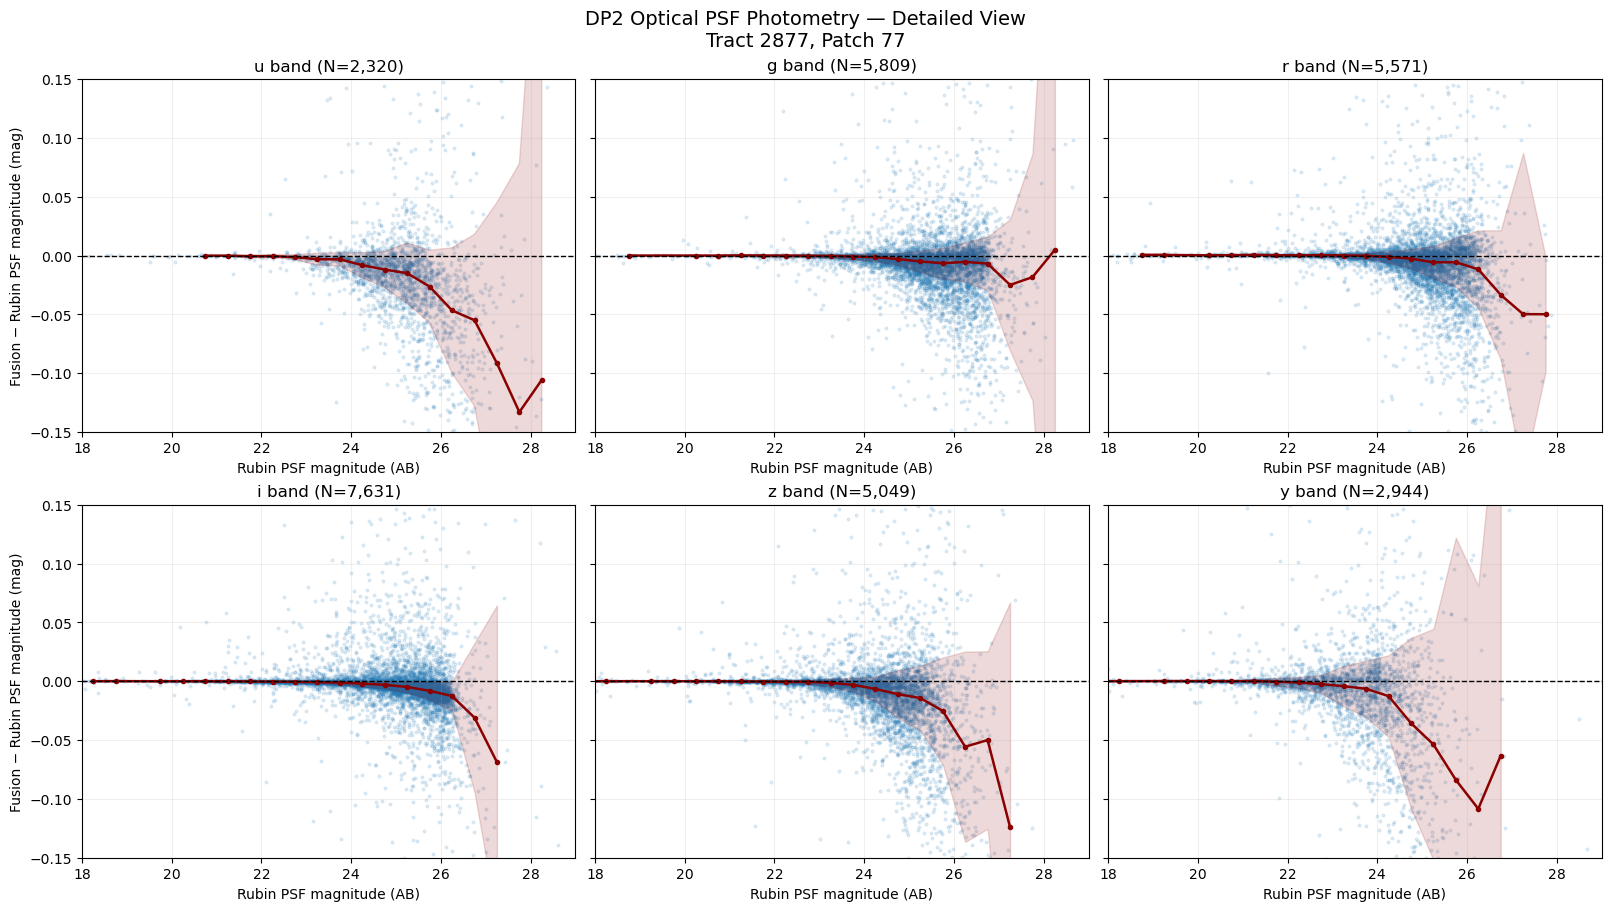

Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/figures/DP2_psf_magnitude_residuals_zoom_2877_77.png


In [10]:
fig, axes = plt.subplots(
    2, 3, figsize=(16, 9),
    sharey=True, constrained_layout=True
)

for ax, band in zip(axes.flat, OPTICAL_BANDS):

    data = photometry_data[band]
    mag = 31.4 - 2.5 * np.log10(data["rubin_flux"])
    delta = data["delta_mag"]

    ax.scatter(
        mag, delta,
        s=4, alpha=0.12,
        rasterized=True
    )

    results = magnitude_results[band]
    x = results["bin_centers"]
    med = results["median"]
    scatter = results["scatter"]

    valid = np.isfinite(med)

    ax.plot(
        x[valid], med[valid],
        color="darkred", marker="o",
        markersize=3, linewidth=1.8
    )

    ax.fill_between(
        x[valid],
        med[valid] - scatter[valid],
        med[valid] + scatter[valid],
        color="darkred", alpha=0.15
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_xlim(18, 29)
    ax.set_ylim(-0.15, 0.15)

    ax.set_title(f"{band} band (N={len(mag):,})")
    ax.set_xlabel("Rubin PSF magnitude (AB)")
    ax.grid(alpha=0.2)

for ax in axes[:, 0]:
    ax.set_ylabel("Fusion − Rubin PSF magnitude (mag)")

fig.suptitle(
    f"DP2 Optical PSF Photometry — Detailed View\n"
    f"Tract {TRACT}, Patch {PATCH}",
    fontsize=14
)

output = FIG_DIR / f"DP2_psf_magnitude_residuals_zoom_{TRACT}_{PATCH}.png"

fig.savefig(output, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", output)

### Magnitude residuals — Results

The six-band comparison reveals a common magnitude-dependent trend.

- Bright sources show negligible systematic differences between
  Rubin DP2 and Fusion PSF measurements.
- At fainter magnitudes, Fusion measurements become systematically
  brighter, producing increasingly negative magnitude residuals.
- The photometric scatter increases toward the faint end, with
  particularly noticeable deviations in u and y.
- The largest faint-end residuals occur where measurements become
  less numerous and less reliable.

The overall agreement remains good for the majority of matched,
valid sources. The faint-end trend may be associated with additive
flux differences, background handling, PSF fitting, deblending,
or measurement-selection effects.


### 5.4. PSF flux differences versus signal-to-noise ratio

Investigate whether the photometric residuals are consistent with
an additive flux difference.

For each optical band, calculate:

$$
\Delta f = f_{\mathrm{Fusion}} - f_{\mathrm{Rubin}}
$$

and use the official Rubin PSF signal-to-noise ratio:

$$
\mathrm{S/N} = \frac{f_{\mathrm{Rubin}}}{\sigma_{f,\mathrm{Rubin}}}
$$

Measure the median flux difference and robust scatter in S/N bins.
A nearly constant flux difference across S/N may indicate an
additive measurement offset rather than a multiplicative
photometric calibration difference.

In [11]:
snr_bins = [(5, 10), (10, 20), (20, 50),
            (50, 100), (100, 1000)]

snr_rows = []

for band in OPTICAL_BANDS:
    d = photometry_data[band]

    snr = d["rubin_flux"] / d["rubin_flux_err"]
    delta_flux = d["delta_flux"]

    for lo, hi in snr_bins:
        sel = (snr >= lo) & (snr < hi)
        values = delta_flux[sel]

        if len(values) == 0:
            continue

        median = np.median(values)
        scatter = 1.4826 * np.median(np.abs(values - median))

        snr_rows.append({
            "Band": band,
            "S/N": f"{lo}–{hi}",
            "N": len(values),
            "Median Δflux (nJy)": median,
            "Robust scatter (nJy)": scatter,
        })

snr_summary = pd.DataFrame(snr_rows)

display(
    snr_summary.pivot(
        index="S/N",
        columns="Band",
        values="Median Δflux (nJy)"
    ).reindex(
        [f"{lo}–{hi}" for lo, hi in snr_bins]
    ).style.format("{:+.3f}")
)

output = RESULT_DIR / f"DP2_psf_flux_vs_snr_{TRACT}_{PATCH}.csv"
snr_summary.to_csv(output, index=False)

print("Saved:", output)

Band,g,i,r,u,y,z
S/N,,,,,,
5–10,+0.583,+1.401,+1.116,+4.554,+8.191,+4.773
10–20,+1.265,+1.312,+1.329,+4.882,+5.667,+4.062
20–50,+1.171,+1.274,+0.508,+3.623,+4.439,+2.640
50–100,+0.940,+1.307,-0.085,+2.988,-1.517,+1.795
100–1000,+0.453,+1.356,-1.347,+1.960,-3.806,+0.991


Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/results/DP2_psf_flux_vs_snr_2877_77.csv


### 7. Export validation results

Save the astrometric and photometric validation statistics for
future comparisons across different DP2 tracts and patches.

In [12]:
import json

summary = {
    "tract": TRACT,
    "patch": PATCH,
    "skymap": SKYMAP,
    "fusion_collection": FUSION_COLLECTION,
    "fusion_sources": int(n_fusion),
    "rubin_objects": int(n_rubin),
    "matched_sources": int(n_matched),
    "unique_rubin_matches": int(n_unique_rubin),
    "rubin_match_fraction": float(n_unique_rubin / n_rubin),
    "median_separation_mas": float(median_sep * 1000),
    "p95_separation_mas": float(p95_sep * 1000),
    "photometry": photometry_summary.to_dict(orient="records"),
}

output = RESULT_DIR / f"DP2_optical_validation_{TRACT}_{PATCH}.json"

with open(output, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", output)

Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/results/DP2_optical_validation_2877_77.json


### Optical reconstruction validation — Summary

The LSST–VISTA Fusion DP2 optical reconstruction has been validated
against the public Rubin DP2 Object catalogue for tract 2877,
patch 77, using all six optical bands (u, g, r, i, z, y).

**Pipeline processing**

- Reconstructed predetection CellCoadds for all six bands.
- Successfully completed optical detection in CellCoadd mode.
- Successfully completed the full multiband Step3c pipeline
  (36 quanta, zero failures).
- Verified consistent source IDs and ordering across all
  six optical measurement catalogues.

**Astrometric validation**

- Fusion catalogue: 13,266 sources.
- Rubin DP2 Object catalogue: 10,005 objects.
- Unique positional matches within 0.5 arcsec: 9,818.
- Rubin catalogue matching fraction: **98.13%**.
- Median positional separation: **5.39 mas**.
- 95th-percentile separation: 174.6 mas.

**Photometric validation**

| Band | Valid matches | Median Δmag | Robust scatter |
|---|---:|---:|---:|
| u | 2,320 | -0.01359 | 0.02214 |
| g | 5,809 | -0.00331 | 0.00909 |
| r | 5,571 | -0.00137 | 0.00938 |
| i | 7,631 | -0.00291 | 0.00532 |
| z | 5,049 | -0.00358 | 0.01096 |
| y | 2,944 | -0.00241 | 0.01652 |

The median magnitude differences are below 0.004 mag in five
of the six bands. The u band shows a larger systematic offset
of approximately -0.014 mag.

Fusion photometry becomes systematically brighter toward faint
magnitudes in all bands, with increasing scatter.

The i-band residual is consistent with an approximately constant
additive flux offset of 1.3 nJy. The other bands show more
variable flux differences as a function of S/N.

**Conclusion**

The reconstructed optical processing produces photometry that
agrees closely with official Rubin DP2 measurements for matched,
valid sources.

The results support proceeding with larger-scale LSST–VISTA
Fusion processing without additional changes to the current
optical reconstruction configuration.

This validation does not establish exact reproduction of the
internal Rubin detection products. Differences in catalogue
selection, faint-source photometry, and unmatched sources
remain to be investigated if required.